# OE1 — Actividad 1: Exploración y entendimiento de VoxForge Spanish

Inventario completo de archivos WAV organizados por sesión. No modifica los audios originales. Ejecutar las celdas en orden desde la raíz del proyecto o desde `notebooks/`.

In [1]:
# 1. Rutas del proyecto
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw" / "voxforge-es"
METADATA = ROOT / "data" / "metadata"
METADATA.mkdir(parents=True, exist_ok=True)

if not RAW.is_dir():
    raise FileNotFoundError(f"No existe el directorio de VoxForge: {RAW}\nVerifica la ubicación del proyecto y la carpeta data/raw/voxforge-es")

print("Proyecto:", ROOT)
print("Corpus:", RAW)
print("Metadatos:", METADATA)

Proyecto: D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal
Corpus: D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\raw\voxforge-es
Metadatos: D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\metadata


In [2]:
# 2. Importar dependencias
import pandas as pd
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")

d:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# 3. Descubrir los audios WAV de todas las sesiones
# Se buscan archivos dentro de carpetas llamadas 'wav', sin importar la profundidad.
audio_files = sorted(
    (p for p in RAW.rglob("*")
     if p.is_file() and p.suffix.lower() == ".wav" and p.parent.name.lower() == "wav"),
    key=lambda p: str(p.relative_to(RAW)).lower()
)

sesiones = sorted({str(p.parent.parent.relative_to(RAW)) for p in audio_files})
print("Archivos WAV encontrados:", len(audio_files))
print("Sesiones con WAV:", len(sesiones))
print("Ejemplo:", audio_files[0].relative_to(RAW) if audio_files else "Sin audios")

if not audio_files:
    raise RuntimeError("No se encontraron archivos .wav en subcarpetas llamadas 'wav'.")

Archivos WAV encontrados: 23537
Sesiones con WAV: 2277
Ejemplo: abarzuaf-20101026-caf\wav\es-0027.wav


In [4]:
# 4. Construir inventario completo sin cargar las señales en memoria
# soundfile.info() lee la cabecera y evita decodificar cada audio completo.
registros = []
for audio in tqdm(audio_files, desc="Inventariando WAV"):
    ruta_relativa = audio.relative_to(RAW).as_posix()
    sesion = audio.parent.parent.relative_to(RAW).as_posix()
    # La ruta relativa garantiza unicidad incluso si hay archivos con el mismo nombre.
    id_audio = ruta_relativa.replace("/", "__")
    fila = {
        "ID_Audio": id_audio,
        "Sesion": sesion,
        "Archivo_original": audio.name,
        "Ruta_relativa": ruta_relativa,
        "Ruta_audio": str(audio.resolve()),
        "Duracion_s": np.nan,
        "Sample_rate": np.nan,
        "Canales": np.nan,
        "Frames": np.nan,
        "Formato": None,
        "Subtipo": None,
        "Tamano_MB": audio.stat().st_size / (1024 ** 2),
        "Estado": "valido",
        "Error": "",
    }
    try:
        info = sf.info(str(audio))
        fila.update({
            "Duracion_s": info.duration,
            "Sample_rate": info.samplerate,
            "Canales": info.channels,
            "Frames": info.frames,
            "Formato": info.format,
            "Subtipo": info.subtype,
        })
        if info.frames <= 0 or info.samplerate <= 0:
            fila["Estado"] = "invalido"
            fila["Error"] = "Duración o frecuencia de muestreo no válida"
    except Exception as exc:
        fila["Estado"] = "invalido"
        fila["Error"] = f"{type(exc).__name__}: {exc}"
    registros.append(fila)

df = pd.DataFrame(registros)
assert df["ID_Audio"].is_unique, "Hay IDs duplicados; revisar las rutas relativas"
print(df["Estado"].value_counts().to_string())
display(df.head())

Inventariando WAV: 100%|██████████| 23537/23537 [09:25<00:00, 41.62it/s]


Estado
valido    23537


,ID_Audio,Sesion,Archivo_original,Ruta_relativa,Ruta_audio,Duracion_s,Sample_rate,Canales,Frames,Formato,Subtipo,Tamano_MB,Estado,Error
0,abarzuaf-20101026-caf__wav__es-0027.wav,abarzuaf-20101026-caf,es-0027.wav,abarzuaf-20101026-caf/wav/es-0027.wav,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,13.625,48000,1,654000,WAV,PCM_16,1.247448,valido,
1,abarzuaf-20101026-caf__wav__es-0028.wav,abarzuaf-20101026-caf,es-0028.wav,abarzuaf-20101026-caf/wav/es-0028.wav,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,11.750,48000,1,564000,WAV,PCM_16,1.075787,valido,
2,abarzuaf-20101026-caf__wav__es-0029.wav,abarzuaf-20101026-caf,es-0029.wav,abarzuaf-20101026-caf/wav/es-0029.wav,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,12.875,48000,1,618000,WAV,PCM_16,1.178783,valido,
3,abarzuaf-20101026-caf__wav__es-0030.wav,abarzuaf-20101026-caf,es-0030.wav,abarzuaf-20101026-caf/wav/es-0030.wav,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,9.875,48000,1,474000,WAV,PCM_16,0.904125,valido,
4,abarzuaf-20101026-caf__wav__es-0031.wav,abarzuaf-20101026-caf,es-0031.wav,abarzuaf-20101026-caf/wav/es-0031.wav,D:\User\Escritorio\tareas\Ciclo 8\ProyectoFina...,11.875,48000,1,570000,WAV,PCM_16,1.087231,valido,


In [5]:
# 5. Estadísticas descriptivas y control de calidad
df_validos = df.loc[df["Estado"] == "valido"].copy()
print("Total:", len(df))
print("Válidos según cabecera:", len(df_validos))
print("Inválidos:", (df["Estado"] == "invalido").sum())
print("Sesiones:", df["Sesion"].nunique())
print("Duración total (horas):", round(df_validos["Duracion_s"].sum() / 3600, 2))
print("Archivos mono:", int((df_validos["Canales"] == 1).sum()))
print("Archivos a 16 kHz:", int((df_validos["Sample_rate"] == 16000).sum()))

display(df_validos[["Duracion_s", "Sample_rate", "Canales", "Tamano_MB"]].describe())
display(df_validos["Sample_rate"].value_counts().rename_axis("Sample_rate").reset_index(name="Cantidad"))
display(df_validos["Canales"].value_counts().rename_axis("Canales").reset_index(name="Cantidad"))

Total: 23537
Válidos según cabecera: 23537
Inválidos: 0
Sesiones: 2277
Duración total (horas): 52.92
Archivos mono: 22694
Archivos a 16 kHz: 0


,Duracion_s,Sample_rate,Canales,Tamano_MB
count,23537.000000,23537.0,23537.000000,23537.000000
mean,8.093675,48000.0,1.035816,0.756042
std,2.322885,0.0,0.185835,0.207461
min,1.300875,48000.0,1.000000,0.119141
25%,6.625000,48000.0,1.000000,0.618023
50%,7.875000,48000.0,1.000000,0.732464
75%,9.500000,48000.0,1.000000,0.875042
max,37.125000,48000.0,2.000000,3.398937


,Sample_rate,Cantidad
0,48000,23537


,Canales,Cantidad
0,1,22694
1,2,843


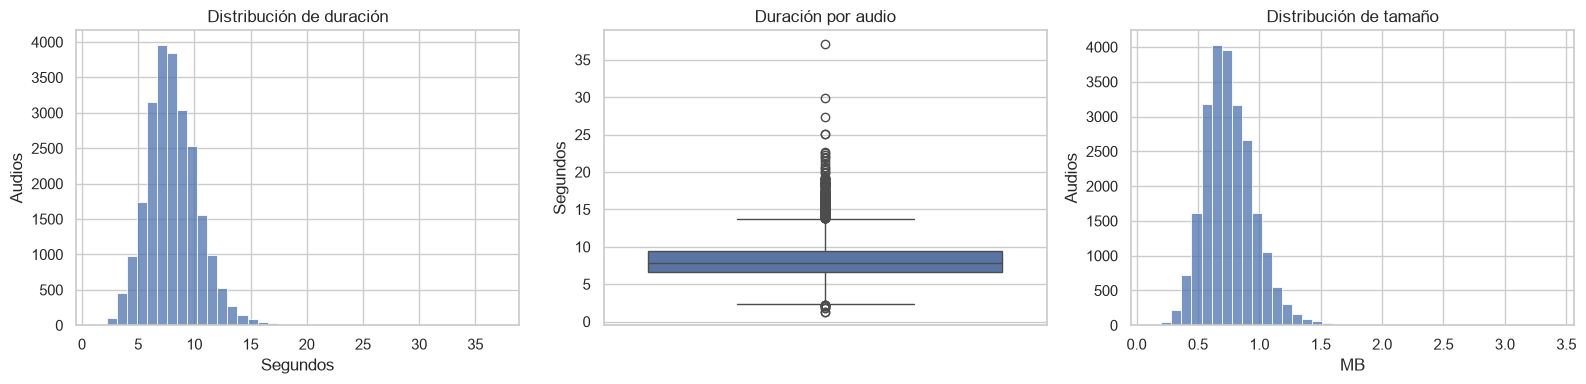

In [6]:
# 6. Gráficas de duración y tamaño
if not df_validos.empty:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    sns.histplot(data=df_validos, x="Duracion_s", bins=40, ax=axes[0])
    axes[0].set(title="Distribución de duración", xlabel="Segundos", ylabel="Audios")
    sns.boxplot(data=df_validos, y="Duracion_s", ax=axes[1])
    axes[1].set(title="Duración por audio", ylabel="Segundos")
    sns.histplot(data=df_validos, x="Tamano_MB", bins=40, ax=axes[2])
    axes[2].set(title="Distribución de tamaño", xlabel="MB", ylabel="Audios")
    plt.tight_layout()
    plt.show()

,Sesion,Cantidad
0,buhochileno_ES_01,140
1,MMarin_ES_01,140
2,JAlvarado_ES_01,140
3,MSolis_ES_01,140
4,ciego-10122009,140
5,PPalma_ES_01,140
6,ubanov_es_01,134
7,AdrianRamirezEscalante-20111202-pgl,10
8,zir0n-20120319-ror,10
9,AGOs-20100831-jdm,10


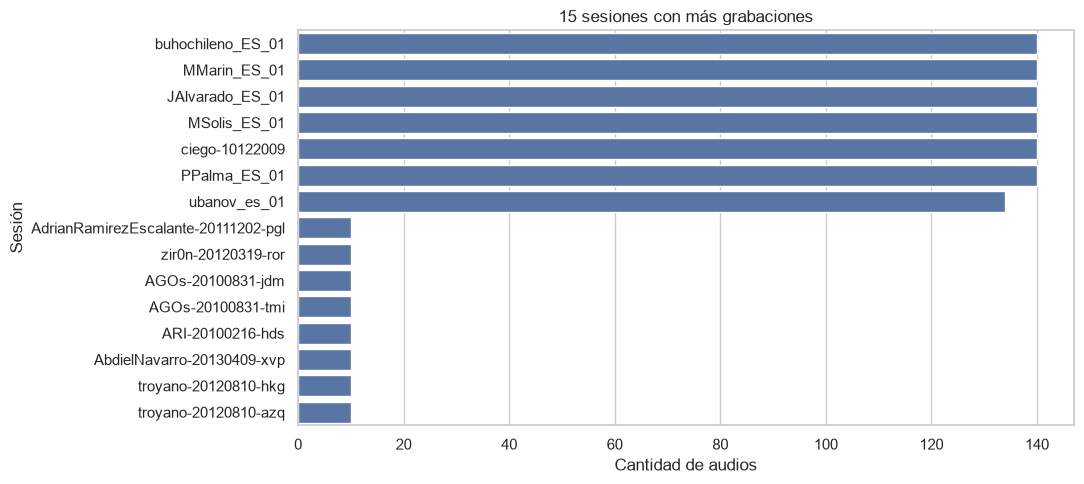

In [7]:
# 7. Distribución de archivos por sesión
conteo_sesiones = df.groupby("Sesion").size().sort_values(ascending=False).rename("Cantidad").reset_index()
display(conteo_sesiones.head(15))

plt.figure(figsize=(11, 5))
sns.barplot(data=conteo_sesiones.head(15), x="Cantidad", y="Sesion")
plt.title("15 sesiones con más grabaciones")
plt.xlabel("Cantidad de audios")
plt.ylabel("Sesión")
plt.tight_layout()
plt.show()

In [8]:
# 8. Guardar inventario completo y errores
inventario_csv = METADATA / "inventario_voxforge.csv"
errores_csv = METADATA / "audios_invalidos_voxforge.csv"
sesiones_csv = METADATA / "resumen_sesiones_voxforge.csv"

df.to_csv(inventario_csv, index=False, encoding="utf-8-sig")
df.loc[df["Estado"] != "valido"].to_csv(errores_csv, index=False, encoding="utf-8-sig")
conteo_sesiones.to_csv(sesiones_csv, index=False, encoding="utf-8-sig")

print("Inventario:", inventario_csv)
print("Errores:", errores_csv)
print("Resumen por sesión:", sesiones_csv)
print("Filas guardadas:", len(df))

Inventario: D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\metadata\inventario_voxforge.csv
Errores: D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\metadata\audios_invalidos_voxforge.csv
Resumen por sesión: D:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\data\metadata\resumen_sesiones_voxforge.csv
Filas guardadas: 23537


In [1]:
# ============================================================
# OE1 - ACTIVIDAD 1
# GENERACIÓN DEL REPORTE PDF DE EXPLORACIÓN DE DATOS
# ============================================================

from pathlib import Path
from datetime import datetime
from xml.sax.saxutils import escape

import pandas as pd
import matplotlib.pyplot as plt

from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    Image,
    KeepTogether
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER, TA_JUSTIFY
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm


# ------------------------------------------------------------
# 1. DEFINIR RUTAS
# ------------------------------------------------------------

# Detectar si el notebook se ejecuta desde la raíz del proyecto
# o desde la carpeta notebooks.

directorio_actual = Path.cwd()

if (directorio_actual / "data").is_dir():
    PROYECTO = directorio_actual

elif (directorio_actual.parent / "data").is_dir():
    PROYECTO = directorio_actual.parent

else:
    raise FileNotFoundError(
        "No se encontró la carpeta data/. "
        "Verifica el directorio de trabajo del notebook."
    )

RUTA_METADATA = PROYECTO / "data" / "metadata"
RUTA_REPORTES = PROYECTO / "reports"

RUTA_REPORTES.mkdir(parents=True, exist_ok=True)

CSV_INVENTARIO = RUTA_METADATA / "inventario_voxforge.csv"

PDF_SALIDA = (
    RUTA_REPORTES / "OE1_01_Reporte_EDA_VoxForge.pdf"
)

if not CSV_INVENTARIO.exists():
    raise FileNotFoundError(
        f"No se encontró el inventario: {CSV_INVENTARIO}"
    )


# ------------------------------------------------------------
# 2. CARGAR RESULTADOS DEL EDA
# ------------------------------------------------------------

df_eda = pd.read_csv(CSV_INVENTARIO)

# Columnas generadas en el inventario
columnas_requeridas = [
    "Duracion_s",
    "Sample_rate",
    "Canales",
    "Tamano_MB"
]

faltantes = [
    col for col in columnas_requeridas
    if col not in df_eda.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas en el inventario: {faltantes}"
    )

# Convertir las métricas a valores numéricos
for col in columnas_requeridas:
    df_eda[col] = pd.to_numeric(
        df_eda[col],
        errors="coerce"
    )

total_audios = len(df_eda)

duracion_total_h = (
    df_eda["Duracion_s"].sum() / 3600
)

duracion_media = df_eda["Duracion_s"].mean()
duracion_min = df_eda["Duracion_s"].min()
duracion_max = df_eda["Duracion_s"].max()

audios_mono = int((df_eda["Canales"] == 1).sum())
audios_estereo = int((df_eda["Canales"] == 2).sum())
audios_16khz = int((df_eda["Sample_rate"] == 16000).sum())
audios_48khz = int((df_eda["Sample_rate"] == 48000).sum())

# Identificar la columna que almacena la sesión
posibles_columnas_sesion = [
    "Sesion",
    "Sesión",
    "Session",
    "ID_Sesion"
]

col_sesion = next(
    (
        col for col in posibles_columnas_sesion
        if col in df_eda.columns
    ),
    None
)

if col_sesion is None:
    raise ValueError(
        "No se encontró la columna de sesión. "
        "Revisa el nombre utilizado en tu inventario."
    )

total_sesiones = df_eda[col_sesion].nunique()

# Contar registros con características técnicas completas
registros_validos = int(
    (
        (df_eda["Duracion_s"] > 0)
        & (df_eda["Sample_rate"] > 0)
        & (df_eda["Canales"] > 0)
    ).sum()
)

registros_invalidos = total_audios - registros_validos


# ------------------------------------------------------------
# 3. CREAR GRÁFICA DE DISTRIBUCIÓN DE CANALES
# ------------------------------------------------------------

RUTA_GRAFICA = (
    RUTA_REPORTES / "distribucion_canales_eda.png"
)

plt.figure(figsize=(6, 3.8))

plt.bar(
    ["Mono", "Estéreo"],
    [audios_mono, audios_estereo],
    color=["#245A81", "#83AEC8"]
)

plt.title("Distribución de canales de audio")
plt.ylabel("Cantidad de archivos")

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(RUTA_GRAFICA, dpi=180)
plt.close()


# ------------------------------------------------------------
# 4. CONFIGURAR ESTILOS DEL PDF
# ------------------------------------------------------------

estilos = getSampleStyleSheet()

estilos.add(
    ParagraphStyle(
        name="TituloReporte",
        parent=estilos["Title"],
        fontSize=17,
        leading=22,
        textColor=colors.HexColor("#173B57"),
        alignment=TA_CENTER,
        spaceAfter=15
    )
)

estilos.add(
    ParagraphStyle(
        name="SeccionReporte",
        parent=estilos["Heading2"],
        fontSize=11,
        leading=15,
        textColor=colors.HexColor("#245A81"),
        spaceBefore=14,
        spaceAfter=8
    )
)

estilos.add(
    ParagraphStyle(
        name="CuerpoReporte",
        parent=estilos["BodyText"],
        fontSize=9.5,
        leading=15,
        alignment=TA_JUSTIFY,
        spaceAfter=9
    )
)

estilos.add(
    ParagraphStyle(
        name="NotaReporte",
        parent=estilos["BodyText"],
        fontSize=8,
        leading=11,
        textColor=colors.HexColor("#555555"),
        alignment=TA_CENTER
    )
)


# ------------------------------------------------------------
# 5. CREAR DOCUMENTO
# ------------------------------------------------------------

documento = SimpleDocTemplate(
    str(PDF_SALIDA),
    pagesize=A4,
    rightMargin=2.2 * cm,
    leftMargin=2.2 * cm,
    topMargin=2 * cm,
    bottomMargin=2 * cm
)

contenido = []

contenido.append(
    Paragraph(
        "REPORTE DE EXPLORACIÓN Y ENTENDIMIENTO DE DATOS",
        estilos["TituloReporte"]
    )
)

contenido.append(
    Paragraph(
        "Objetivo específico 1 - Actividad 1",
        estilos["NotaReporte"]
    )
)

contenido.append(Spacer(1, 0.4 * cm))

contenido.append(
    Paragraph(
        f"Dataset: VoxForge Spanish<br/>"
        f"Fecha de generación: {datetime.now():%d/%m/%Y}",
        estilos["CuerpoReporte"]
    )
)


# ------------------------------------------------------------
# 6. SECCIÓN 1: RESUMEN DEL DATASET
# ------------------------------------------------------------

contenido.append(
    Paragraph(
        "1. Resumen general del conjunto de datos",
        estilos["SeccionReporte"]
    )
)

contenido.append(
    Paragraph(
        "Durante la fase de exploración y entendimiento de datos "
        "se analizaron las grabaciones del corpus VoxForge Spanish, "
        "organizadas en directorios correspondientes a sesiones de "
        "grabación. Se realizó una inspección técnica de los archivos "
        "para identificar su cantidad, duración, frecuencia de "
        "muestreo, canales y posibles registros inválidos.",
        estilos["CuerpoReporte"]
    )
)

datos_resumen = [
    ["Indicador", "Resultado"],
    ["Total de archivos", f"{total_audios:,}"],
    ["Registros válidos según metadatos", f"{registros_validos:,}"],
    ["Registros inválidos", str(registros_invalidos)],
    ["Sesiones identificadas", f"{total_sesiones:,}"],
    ["Duración total", f"{duracion_total_h:.2f} horas"],
    ["Duración promedio", f"{duracion_media:.2f} segundos"]
]

tabla_resumen = Table(
    datos_resumen,
    colWidths=[10 * cm, 5 * cm]
)

tabla_resumen.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#245A81")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [
            colors.white,
            colors.HexColor("#F0F4F7")
        ]),
        ("GRID", (0, 0), (-1, -1), 0.3, colors.lightgrey),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
        ("TOPPADDING", (0, 0), (-1, -1), 7)
    ])
)

contenido.append(tabla_resumen)


# ------------------------------------------------------------
# 7. SECCIÓN 2: CARACTERÍSTICAS TÉCNICAS
# ------------------------------------------------------------

contenido.append(
    Paragraph(
        "2. Características técnicas de los archivos",
        estilos["SeccionReporte"]
    )
)

datos_tecnicos = [
    ["Característica", "Resultado"],
    ["Frecuencia de muestreo de 48 kHz", str(audios_48khz)],
    ["Frecuencia de muestreo de 16 kHz", str(audios_16khz)],
    ["Archivos mono", str(audios_mono)],
    ["Archivos estéreo", str(audios_estereo)],
    ["Duración mínima", f"{duracion_min:.2f} s"],
    ["Duración máxima", f"{duracion_max:.2f} s"],
    ["Tamaño promedio", f"{df_eda['Tamano_MB'].mean():.2f} MB"]
]

tabla_tecnica = Table(
    datos_tecnicos,
    colWidths=[10 * cm, 5 * cm]
)

tabla_tecnica.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#245A81")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [
            colors.white,
            colors.HexColor("#F0F4F7")
        ]),
        ("GRID", (0, 0), (-1, -1), 0.3, colors.lightgrey),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
        ("TOPPADDING", (0, 0), (-1, -1), 7)
    ])
)

contenido.append(tabla_tecnica)

contenido.append(Spacer(1, 0.4 * cm))

contenido.append(
    Image(
        str(RUTA_GRAFICA),
        width=13 * cm,
        height=8.2 * cm
    )
)

contenido.append(
    Paragraph(
        "Figura 1. Distribución de los archivos según el número de canales.",
        estilos["NotaReporte"]
    )
)


# ------------------------------------------------------------
# 8. SECCIÓN 3: ANÁLISIS Y RECOMENDACIONES
# ------------------------------------------------------------

contenido.append(
    Paragraph(
        "3. Análisis de los resultados",
        estilos["SeccionReporte"]
    )
)

porcentaje_mono = (
    audios_mono / total_audios * 100
    if total_audios else 0
)

porcentaje_estereo = (
    audios_estereo / total_audios * 100
    if total_audios else 0
)

analisis = (
    f"El análisis identificó {total_audios:,} grabaciones "
    f"distribuidas en {total_sesiones:,} sesiones, con una duración "
    f"acumulada de {duracion_total_h:.2f} horas. "
    f"El {porcentaje_mono:.2f}% de los archivos corresponde a "
    f"grabaciones mono, mientras que el {porcentaje_estereo:.2f}% "
    f"corresponde a grabaciones estéreo. "
    f"Se identificaron {audios_48khz:,} archivos a 48 kHz y "
    f"{audios_16khz:,} archivos a 16 kHz."
)

contenido.append(
    Paragraph(
        escape(analisis),
        estilos["CuerpoReporte"]
    )
)

contenido.append(
    Paragraph(
        "Para la siguiente actividad se recomienda estandarizar "
        "los archivos a formato WAV mono de 16 kHz, conservar "
        "identificadores únicos por sesión y verificar la "
        "integridad de los archivos convertidos. "
        "La inspección de cabeceras no sustituye una revisión "
        "de la calidad acústica ni de la correspondencia con "
        "las transcripciones de referencia.",
        estilos["CuerpoReporte"]
    )
)


# ------------------------------------------------------------
# 9. PIE DE PÁGINA
# ------------------------------------------------------------

def agregar_pie(canvas, doc):
    canvas.saveState()

    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)

    canvas.drawString(
        2.2 * cm,
        1.3 * cm,
        "VoxForge Spanish - Reporte EDA"
    )

    canvas.drawRightString(
        A4[0] - 2.2 * cm,
        1.3 * cm,
        f"Página {doc.page}"
    )

    canvas.restoreState()


# ------------------------------------------------------------
# 10. GENERAR PDF
# ------------------------------------------------------------

documento.build(
    contenido,
    onFirstPage=agregar_pie,
    onLaterPages=agregar_pie
)

print("Reporte PDF generado correctamente:")
print(PDF_SALIDA)

Reporte PDF generado correctamente:
d:\User\Escritorio\tareas\Ciclo 8\ProyectoFinal\reports\OE1_01_Reporte_EDA_VoxForge.pdf
